# 05 — Clustering: are there typical patient profiles?

**Input:** `../data/processed/OSA_DB_UPM_BMI_classes.xlsx` (637 patients, output of `src/01_data_preparation.py`)
**Output:** results tables in `../results/`, figures in `../figures/`

**Question (unsupervised):** without using IAH or the OSA class, do patients form natural groups based on their clinical variables? Only **afterwards** we check whether these groups differ in OSA severity (hypothesis H4: clusters exist but do not match the OSA classes exactly).

**Methods compared:** k-means, hierarchical clustering (Ward linkage) and Gaussian Mixture Model (GMM).

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score

warnings.filterwarnings("ignore")
SEED = 42
DATA = Path("../data/processed/OSA_DB_UPM_BMI_classes.xlsx")
FIG = Path("../figures"); FIG.mkdir(parents=True, exist_ok=True)
RES = Path("../results"); RES.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

## 1. Data and features
**Clustering variables:** Age, Weight, Height, Cervical (neck circumference) and BMI.

**Why gender is not a clustering variable.** Gender is binary (0/1). After standardisation it creates a large, artificial gap between two groups, so distance-based methods simply split men from women (tested: with gender included, the 2-cluster solution matches gender almost perfectly). A binary variable is also not Gaussian, which breaks the GMM assumption. Gender is therefore kept **aside** and used afterwards to describe the clusters — the same for IAH and the OSA class.

**Standardisation** (mean 0, std 1) is required: all three methods rely on distances or variances, and without it weight (range ≈ 100 kg) would dominate neck (range ≈ 20 cm).

In [2]:
df = pd.read_excel(DATA)
df["Male"] = (df["Gender"] == "hombre").astype(int)
FEATURES = ["Age", "Weight", "Height", "Cervical", "BMI"]
Z = StandardScaler().fit_transform(df[FEATURES])
print(Z.shape)
df[FEATURES].describe().round(1)

(637, 5)


,Age,Weight,Height,Cervical,BMI
count,637.0,637.0,637.0,637.0,637.0
mean,49.5,87.7,171.3,40.6,29.9
std,12.4,18.4,9.6,4.0,5.6
min,20.0,45.0,144.0,30.0,18.3
25%,40.0,75.0,165.0,38.0,26.0
50%,49.0,86.0,171.0,41.0,28.7
75%,59.0,98.0,178.0,43.0,32.8
max,88.0,165.0,197.0,53.0,63.7


## 2. How many clusters?
For k = 2 … 8:
- **Elbow (k-means inertia):** total squared distance of patients to their cluster centre. It always decreases with k; we look for the point where adding clusters stops helping much.
- **Silhouette score** (all methods): for each patient, compares the distance to its own cluster with the distance to the nearest other cluster. From −1 to 1; higher = compact, well-separated clusters. Values below ~0.3 mean weak structure.
- **BIC (GMM):** likelihood of the data penalised by the number of parameters. Lower is better.

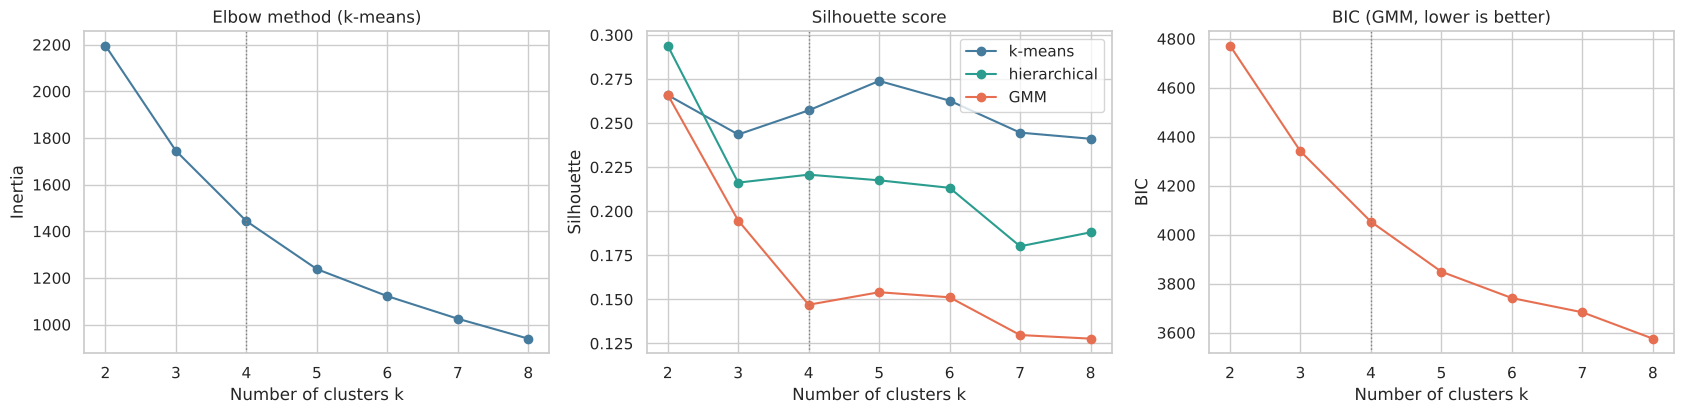

,k,Inertia (k-means),Silhouette k-means,Silhouette hierarchical,Silhouette GMM,BIC (GMM)
0,2,2195.912,0.266,0.294,0.266,4771.899
1,3,1744.854,0.244,0.216,0.195,4340.383
2,4,1443.538,0.257,0.221,0.147,4052.885
3,5,1237.737,0.274,0.218,0.154,3848.766
4,6,1121.942,0.263,0.213,0.151,3741.234
5,7,1025.049,0.245,0.180,0.130,3683.140
6,8,939.680,0.241,0.188,0.128,3575.481


In [3]:
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z)
    hc = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(Z)
    gm = GaussianMixture(n_components=k, n_init=5, random_state=SEED).fit(Z)
    rows.append({"k": k, "Inertia (k-means)": km.inertia_,
                 "Silhouette k-means": silhouette_score(Z, km.labels_),
                 "Silhouette hierarchical": silhouette_score(Z, hc.labels_),
                 "Silhouette GMM": silhouette_score(Z, gm.predict(Z)),
                 "BIC (GMM)": gm.bic(Z)})
choice = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
axes[0].plot(choice.k, choice["Inertia (k-means)"], "o-", color="#457b9d")
axes[0].set(title="Elbow method (k-means)", xlabel="Number of clusters k", ylabel="Inertia")
for col, c in [("Silhouette k-means", "#457b9d"), ("Silhouette hierarchical", "#2a9d8f"), ("Silhouette GMM", "#e76f51")]:
    axes[1].plot(choice.k, choice[col], "o-", color=c, label=col.replace("Silhouette ", ""))
axes[1].set(title="Silhouette score", xlabel="Number of clusters k", ylabel="Silhouette")
axes[1].legend()
axes[2].plot(choice.k, choice["BIC (GMM)"], "o-", color="#e76f51")
axes[2].set(title="BIC (GMM, lower is better)", xlabel="Number of clusters k", ylabel="BIC")
for ax in axes: ax.axvline(4, color="grey", ls=":", lw=1)
plt.tight_layout(); plt.savefig(FIG / "clu_01_choosing_k.png", dpi=200); plt.show()
choice.round(3)

**Choice: k = 4.**
- The silhouette scores are low for every k (≈ 0.15–0.30): the patients do **not** form well-separated natural groups — consistent with the PCA of the EDA (one continuous cloud).
- k = 2 has the highest silhouette, but it only separates "heavy" from "light" patients, which says little.
- Among k ≥ 3, k = 4 gives one of the best k-means silhouettes, the elbow flattens around 4–5, and the four profiles are clinically interpretable (Section 4).
- The GMM BIC keeps decreasing with k (more components always fit better here), so it does not give a clear optimum.

With weak structure, the choice of k is partly a **modelling decision** guided by interpretability, which must be stated in the report.

In [4]:
K = 4
km = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(Z)
hc = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(Z)
gm = GaussianMixture(n_components=K, n_init=5, random_state=SEED).fit(Z)
df["kmeans"], df["hierarchical"], df["gmm"] = km.labels_, hc.labels_, gm.predict(Z)

# Cluster numbers are arbitrary: renumber the hierarchical and GMM clusters so that they
# match the k-means clusters as closely as possible (only for readable plots and tables)
from scipy.optimize import linear_sum_assignment
def align(ref, lab):
    cm = pd.crosstab(lab, ref).reindex(index=range(K), columns=range(K), fill_value=0).to_numpy()
    rows, cols = linear_sum_assignment(-cm)
    return pd.Series(lab).map(dict(zip(rows, cols))).to_numpy()
df["hierarchical"] = align(df["kmeans"], df["hierarchical"])
df["gmm"] = align(df["kmeans"], df["gmm"])
pd.crosstab(df["kmeans"], df["gmm"], rownames=["k-means"], colnames=["GMM"])

GMM,0,1,2,3
k-means,,,,
0,82,22,28,43
1,46,141,6,10
2,11,3,132,1
3,20,22,0,70


## 3. The clusters in two dimensions
The clusters are shown on the first two principal components of the five standardised variables (as in the EDA). PCA is only used for the picture; the clustering itself uses all five variables.

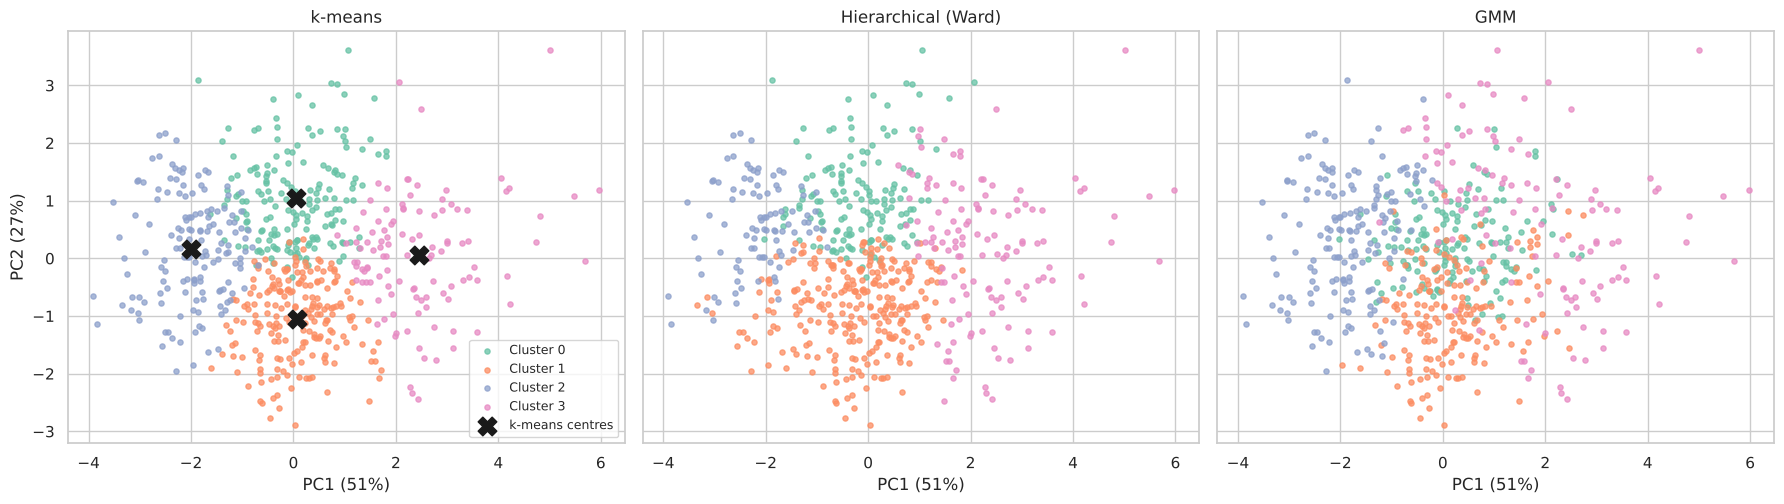

,PC1,PC2
Age,-0.08,0.66
Weight,0.61,0.03
Height,0.32,-0.62
Cervical,0.53,0.06
BMI,0.49,0.42


In [5]:
pca = PCA(n_components=2).fit(Z)
P = pca.transform(Z)
ev = pca.explained_variance_ratio_
pal = sns.color_palette("Set2", K)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), sharex=True, sharey=True)
for ax, method in zip(axes, ["kmeans", "hierarchical", "gmm"]):
    for c in range(K):
        m = df[method] == c
        ax.scatter(P[m, 0], P[m, 1], s=14, alpha=0.75, color=pal[c], label=f"Cluster {c}")
    ax.set(title={"kmeans": "k-means", "hierarchical": "Hierarchical (Ward)", "gmm": "GMM"}[method],
           xlabel=f"PC1 ({ev[0]:.0%})")
axes[0].set_ylabel(f"PC2 ({ev[1]:.0%})")
centres = pca.transform(km.cluster_centers_)
axes[0].scatter(centres[:, 0], centres[:, 1], marker="X", s=180, color="k", label="k-means centres")
axes[0].legend(fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "clu_02_clusters_pca.png", dpi=200); plt.show()

loadings = pd.DataFrame(pca.components_.T, index=FEATURES, columns=["PC1", "PC2"]).round(2)
loadings

## 4. Dendrogram (hierarchical clustering)
Each merge is drawn at the height (Ward distance) where two groups are joined. The tree is truncated to its last 30 merges. A large vertical gap before a merge suggests a natural number of clusters; the dotted line shows the cut giving 4 clusters.

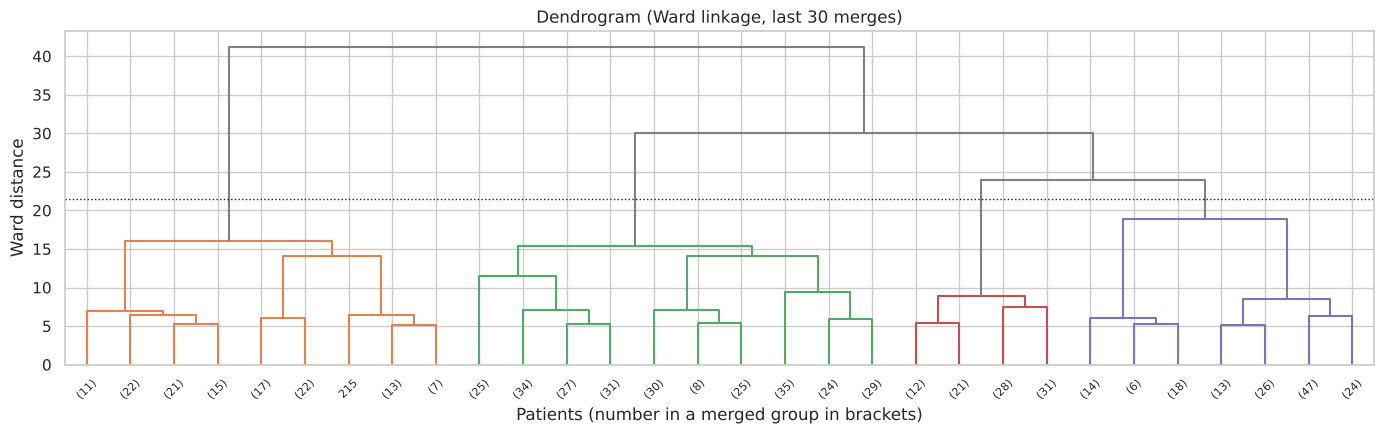

In [6]:
L = linkage(Z, method="ward")
cut = (L[-K, 2] + L[-K + 1, 2]) / 2
fig, ax = plt.subplots(figsize=(14, 4.5))
dendrogram(L, truncate_mode="lastp", p=30, color_threshold=cut, above_threshold_color="grey", ax=ax, leaf_font_size=8)
ax.axhline(cut, color="k", ls=":", lw=1)
ax.set(title="Dendrogram (Ward linkage, last 30 merges)", xlabel="Patients (number in a merged group in brackets)", ylabel="Ward distance")
plt.tight_layout(); plt.savefig(FIG / "clu_03_dendrogram.png", dpi=200); plt.show()

## 5. Who is in each cluster? (k-means)
Each cluster is described by the mean of the clustering variables and by the share of men (gender was **not** used to build the clusters). The heatmap shows the cluster centres in standard deviations from the overall mean (red = above average, blue = below).

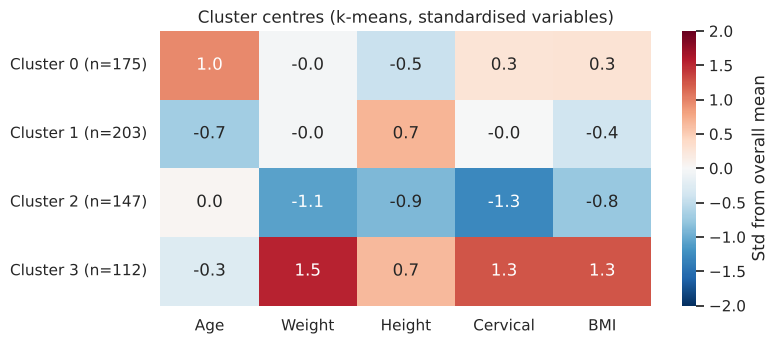

,Patients,Age,Weight,Height,Cervical,BMI,Men_pct
kmeans,,,,,,,
0,175,61.3,87.1,167.0,41.7,31.4,72.0
1,203,40.9,87.1,177.7,40.6,27.7,93.6
2,147,49.9,67.8,162.8,35.5,25.7,23.1
3,112,46.0,116.0,177.5,45.6,36.9,93.8


In [7]:
profile = df.groupby("kmeans").agg(
    Patients=("IAH", "size"), Age=("Age", "mean"), Weight=("Weight", "mean"), Height=("Height", "mean"),
    Cervical=("Cervical", "mean"), BMI=("BMI", "mean"), Men_pct=("Male", lambda s: 100 * s.mean()))
centres_std = pd.DataFrame(km.cluster_centers_, columns=FEATURES)

fig, ax = plt.subplots(figsize=(8, 3.6))
sns.heatmap(centres_std, annot=True, fmt=".1f", cmap="RdBu_r", center=0, vmin=-2, vmax=2, ax=ax,
            yticklabels=[f"Cluster {c} (n={n})" for c, n in profile["Patients"].items()],
            cbar_kws={"label": "Std from overall mean"})
ax.set_title("Cluster centres (k-means, standardised variables)")
plt.tight_layout(); plt.savefig(FIG / "clu_04_cluster_profiles.png", dpi=200); plt.show()
profile.round(1)

## 6. Do the clusters differ in OSA severity? (IAH and class used only now)
- **Distribution of OSA classes** in each cluster.
- **IAH** per cluster, with a Kruskal-Wallis test (non-parametric comparison of more than two groups).
- **Chi-square test**: is the OSA class independent of the cluster?

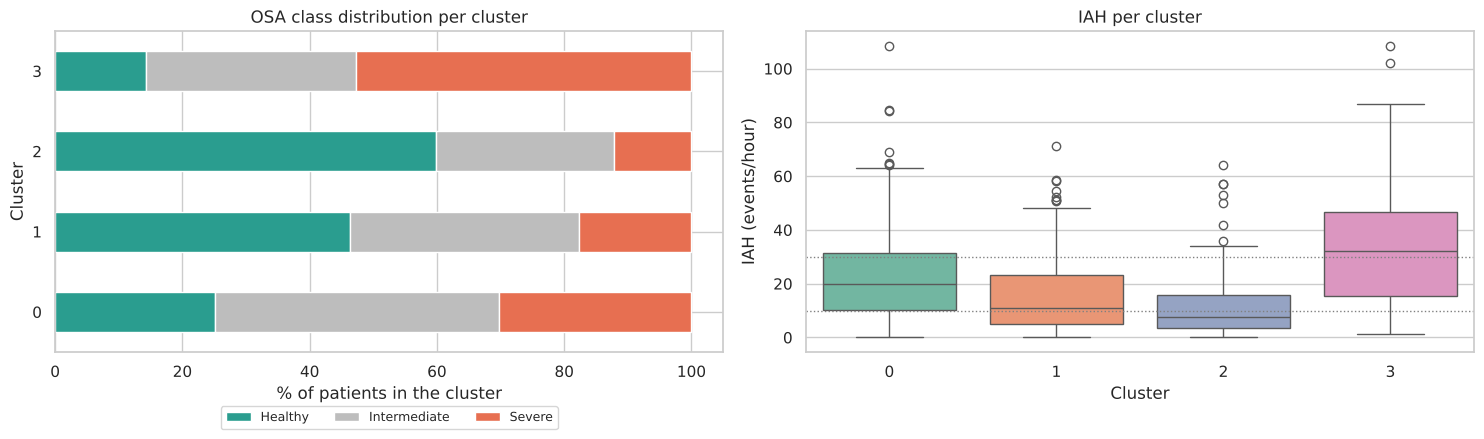

Kruskal-Wallis (IAH across clusters): H = 112.9, p = 2.6e-24
Chi-square (OSA class vs cluster):    chi2 = 100.7, dof = 6, p = 1.8e-19


,Patients,Age,Weight,Height,Cervical,BMI,Men_pct,IAH median,IAH mean,Healthy %,Intermediate %,Severe %
kmeans,,,,,,,,,,,,
0,175,61.3,87.1,167.0,41.7,31.4,72.0,19.8,23.2,25.1,44.6,30.3
1,203,40.9,87.1,177.7,40.6,27.7,93.6,10.9,16.0,46.3,36.0,17.7
2,147,49.9,67.8,162.8,35.5,25.7,23.1,7.6,12.0,59.9,27.9,12.2
3,112,46.0,116.0,177.5,45.6,36.9,93.8,32.0,35.0,14.3,33.0,52.7


In [8]:
sev = pd.crosstab(df["kmeans"], df["OSA"], normalize="index")[["Healthy", "Intermediate", "Severe"]] * 100
iah = df.groupby("kmeans")["IAH"].agg(["median", "mean"])
summary = profile.join(iah.rename(columns={"median": "IAH median", "mean": "IAH mean"})).join(sev.add_suffix(" %"))
summary.round(1).to_csv(RES / "clustering_kmeans_profiles.csv")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
sev.plot.barh(stacked=True, ax=axes[0], color={"Healthy": "#2a9d8f", "Intermediate": "#bdbdbd", "Severe": "#e76f51"})
axes[0].set(title="OSA class distribution per cluster", xlabel="% of patients in the cluster", ylabel="Cluster")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, fontsize=9)
sns.boxplot(data=df, x="kmeans", y="IAH", hue="kmeans", palette=pal, legend=False, ax=axes[1])
for t in (10, 30): axes[1].axhline(t, color="grey", ls=":", lw=1)
axes[1].set(title="IAH per cluster", xlabel="Cluster", ylabel="IAH (events/hour)")
plt.tight_layout(); plt.savefig(FIG / "clu_05_severity_by_cluster.png", dpi=200); plt.show()

h, p_kw = stats.kruskal(*[g["IAH"] for _, g in df.groupby("kmeans")])
chi2, p_chi, dof, _ = stats.chi2_contingency(pd.crosstab(df["kmeans"], df["OSA"]))
print(f"Kruskal-Wallis (IAH across clusters): H = {h:.1f}, p = {p_kw:.1e}")
print(f"Chi-square (OSA class vs cluster):    chi2 = {chi2:.1f}, dof = {dof}, p = {p_chi:.1e}")
summary.round(1)

## 7. Agreement between methods, and with known labels
**Adjusted Rand Index (ARI):** similarity between two partitions of the same patients. 1 = identical, 0 = no more agreement than chance (cluster numbers do not need to match).

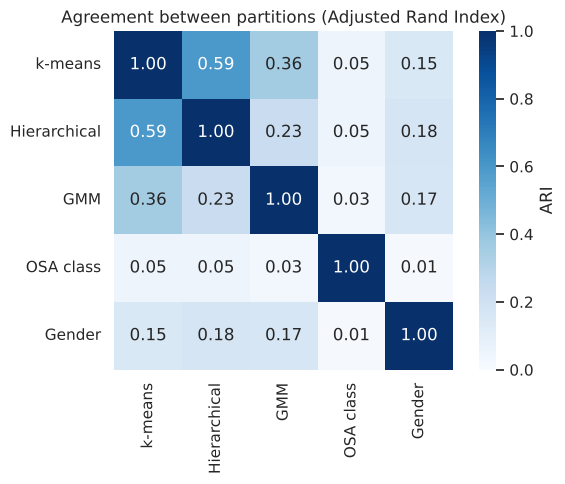

,k-means,Hierarchical,GMM,OSA class,Gender
k-means,1.00,0.59,0.36,0.05,0.15
Hierarchical,0.59,1.00,0.23,0.05,0.18
GMM,0.36,0.23,1.00,0.03,0.17
OSA class,0.05,0.05,0.03,1.00,0.01
Gender,0.15,0.18,0.17,0.01,1.00


In [9]:
parts = {"k-means": df["kmeans"], "Hierarchical": df["hierarchical"], "GMM": df["gmm"],
         "OSA class": df["OSA"], "Gender": df["Gender"]}
names = list(parts)
ari = pd.DataFrame([[adjusted_rand_score(parts[a], parts[b]) for b in names] for a in names], index=names, columns=names)

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(ari, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, square=True, ax=ax, cbar_kws={"label": "ARI"})
ax.set_title("Agreement between partitions (Adjusted Rand Index)")
plt.tight_layout(); plt.savefig(FIG / "clu_06_agreement_ari.png", dpi=200); plt.show()
ari.round(2)

## 8. GMM: soft membership
Unlike k-means, the GMM gives each patient a **probability** of belonging to each cluster. A patient whose highest probability is low lies between clusters.

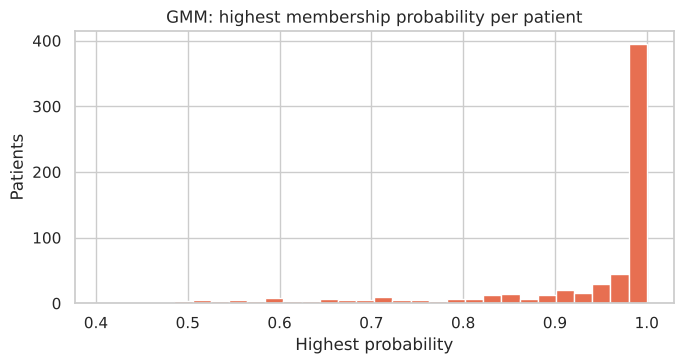

Patients assigned with probability < 0.8: 13%


In [10]:
proba = gm.predict_proba(Z).max(axis=1)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(proba, bins=30, color="#e76f51")
ax.set(title="GMM: highest membership probability per patient", xlabel="Highest probability", ylabel="Patients")
plt.tight_layout(); plt.savefig(FIG / "clu_07_gmm_membership.png", dpi=200); plt.show()
print(f"Patients assigned with probability < 0.8: {(proba < 0.8).mean():.0%}")

## 9. Bonus — the GMM as a generative model
A GMM is a full model of the data distribution p(x): we can **sample new, synthetic patients** from it. If the model is good, synthetic patients should have the same statistics as real ones (means, spreads, and correlations such as weight–BMI). This is the link with **generative models** discussed in class.

Spearman correlation Weight–BMI:  real 0.82   synthetic 0.82


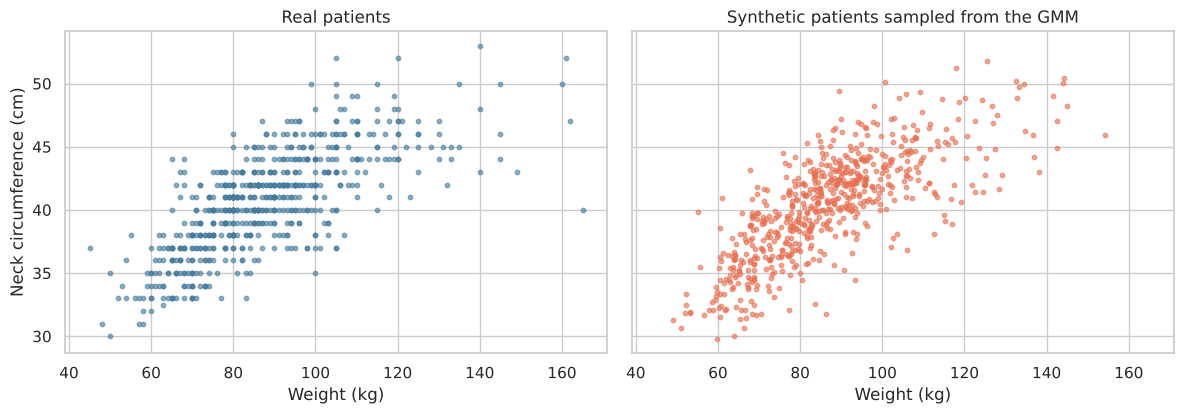

,Real mean,Synthetic mean,Real std,Synthetic std
Age,49.5,50.1,12.4,12.5
Weight,87.7,87.0,18.4,17.7
Height,171.3,171.0,9.6,9.4
Cervical,40.6,40.4,4.0,4.1
BMI,29.9,29.7,5.6,5.3


In [11]:
S, _ = gm.sample(len(df))
synth = pd.DataFrame(StandardScaler().fit(df[FEATURES]).inverse_transform(S), columns=FEATURES)
comp = pd.DataFrame({"Real mean": df[FEATURES].mean(), "Synthetic mean": synth.mean(),
                     "Real std": df[FEATURES].std(), "Synthetic std": synth.std()}).round(1)
print("Spearman correlation Weight–BMI:  real %.2f   synthetic %.2f" % (
    stats.spearmanr(df["Weight"], df["BMI"])[0], stats.spearmanr(synth["Weight"], synth["BMI"])[0]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharex=True, sharey=True)
axes[0].scatter(df["Weight"], df["Cervical"], s=10, alpha=0.6, color="#457b9d")
axes[0].set(title="Real patients", xlabel="Weight (kg)", ylabel="Neck circumference (cm)")
axes[1].scatter(synth["Weight"], synth["Cervical"], s=10, alpha=0.6, color="#e76f51")
axes[1].set(title="Synthetic patients sampled from the GMM", xlabel="Weight (kg)")
plt.tight_layout(); plt.savefig(FIG / "clu_08_gmm_synthetic_patients.png", dpi=200); plt.show()
comp

## 10. Conclusions
*(to be written in the report from the outputs above)*